#### Does the dynamics model matter?

**Model selection:** Set `MODEL_NAME` below to a supported Qwen model or `roneneldan/TinyStories-28M`, then rerun from the top. Directions, Jacobians, and results are stored in separate model-specific artifact directories. Uncached Jacobians use `efficient_mean_jacobian`; existing cached matrices remain compatible and are reused.

**Hypothesis.** With the plain (Euclidean) A-LQR cost and a push after every block, the linear block model barely changes steering quality once concept strength is matched, because the controller re-measures $v^\top x$ at every block and corrects the model's mistakes. With sparse actuation, it has to rely on the model between pushes, so the models should separate as pushes get sparser.

| Symbol | Meaning |
|---|---|
| $x_\ell$ | last token's state entering block $\ell$ |
| $v_\ell = E_\ell / \|E_\ell\|$ | concept direction |
| $u_\ell = (\lambda\|E_\ell\| - v_\ell^\top x_\ell)\,K_\ell v_\ell$ | push after block $\ell$ |
| $A_\ell$ | linear model of block $\ell$, $\delta x_{\ell+1} \approx A_\ell\,\delta x_\ell + u_\ell$; sets $K_\ell$ through the Riccati recursion |
| $m$ | sparse actuation: measure and push only after blocks $0, m, 2m, \dots$ (`EVERY`); $m = 1$ is every block |
| $S_\ell$ | Riccati cost-to-go; at blocks without a push, $K_\ell = 0$ and $S_\ell = qI + A_\ell^\top S_{\ell+1} A_\ell$ |

With $m > 1$, each push plans across the $m - 1$ free blocks after it through the chain $A_{\ell+m-1}\cdots A_{\ell+1}$, and nothing corrects it until the next push.

Three models:

| Model | $A_\ell$ | Role |
|---|---|---|
| Identity | $I$ | no model |
| Mean Jacobian | $\bar J_\ell$, averaged over concept prompts | a real model |
| Random | $I + B_\ell$, Gaussian $B_\ell$ with $\|B_\ell\|_F = \|\bar J_\ell - I\|_F$ | a wrong model of the same size |

The $\lambda$ range covers the concept switching on and coherence falling. Each $\lambda$ uses the same sampling seed for every model.

**Readouts**
1. Rates per $m$, model and $\lambda$.
2. Coherence against the judged concept rate, and against the along-$v$ shift, one curve per model, one row of panels per $m$.
3. The best "both" rate (on-concept and coherent) across $\lambda$, per $m$.
4. Coherence at the same along-$v$ shift, per $m$.

With 100 completions, a rate is uncertain by about $\pm 0.05$ and a difference between two rates by about $\pm 0.07$. The hypothesis holds if the curves overlap within that at $m = 1$ on both LLMs and separate as $m$ grows. If they never separate, the model does not matter for this steering at any sparsity.

In [1]:
from pathlib import Path
import gc, importlib, random, sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'llm' / 'steering.py').is_file())
sys.path.insert(0, str(REPO_ROOT))
import llm.model, llm.concepts, llm.jacobian, llm.steering, llm.trace, llm.judge
for module in (llm.model, llm.concepts, llm.jacobian, llm.steering, llm.trace, llm.judge):
    importlib.reload(module)
from llm.model import load_model, blocks
from llm.concepts import concept_direction, load_concept_prompts
from llm.jacobian import efficient_mean_jacobian
from llm.steering import LQRSteering, sample
from llm.trace import trace, completion_metrics
from llm.judge import build_judge, concept_criterion, COHERENCE, repetition

# MODEL_NAME = 'Qwen/Qwen3-4B'
MODEL_NAME = 'Qwen/Qwen3-4B'
CONCEPT = 'football'
PROMPT = 'Once upon a time'
SEED = 0

DIRECTION_SAMPLES = 200    # target and background sentences, each
JACOBIAN_SAMPLES = 50      # target sentences averaged into the mean Jacobian
MAX_CTX = 32
BATCH_SIZE = 8
RANDOM_SEED = 0            # seed of the random model

Q, R, QF = 0.1, 10, 0.1
STEER_LAST_N_LAYERS = None  # None = all blocks
EVERY = (1, 2, 3, 4)          # push after every m-th block (sparse actuation); 1 = every block
LAMBDAS = (0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4.0)
TRIALS = 100                # completions per sparsity, model and lambda
MAX_NEW_TOKENS = 96
TEMPERATURE, TOP_P = 0.7, 0.95
JUDGE_BATCH = 128             # responses per GPU forward; reduce if GPU memory is limited

/home/dunstan/git/kae-steering/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
random.seed(SEED)
torch.manual_seed(SEED)
tokenizer, model = load_model(MODEL_NAME)
NUM_LAYERS = len(blocks(model))
HIDDEN = model.get_input_embeddings().weight.shape[1]
PROMPT_LEN = len(tokenizer(PROMPT)['input_ids'])
ARTIFACTS = REPO_ROOT / 'artifacts' / MODEL_NAME.rsplit('/', 1)[-1].lower()
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print(f'{MODEL_NAME}: {NUM_LAYERS} blocks, hidden {HIDDEN}, {next(model.parameters()).dtype}')

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 541.07it/s]


Qwen/Qwen3-4B: 36 blocks, hidden 2560, torch.bfloat16


In [3]:
E_PATH = ARTIFACTS / f'E_{CONCEPT}_n{DIRECTION_SAMPLES}_seed{SEED}.pt'
if E_PATH.exists():
    E = torch.load(E_PATH, weights_only=True)
else:
    random.seed(SEED)
    E = concept_direction(model, tokenizer, CONCEPT, DIRECTION_SAMPLES, BATCH_SIZE)
    torch.save(E, E_PATH)
print('E:', tuple(E.shape))

E: (37, 2560)


In [4]:
A_PATH = ARTIFACTS / f'A_{CONCEPT}_n{JACOBIAN_SAMPLES}_ctx{MAX_CTX}_seed{SEED}.pt'
if A_PATH.exists():
    A_jac = torch.load(A_PATH, weights_only=True)
else:
    random.seed(SEED + 1)
    targets, _ = load_concept_prompts(CONCEPT, JACOBIAN_SAMPLES)
    A_jac = efficient_mean_jacobian(model, tokenizer, targets, max_ctx=MAX_CTX)
    torch.save(A_jac, A_PATH)

B_random = torch.randn(NUM_LAYERS, HIDDEN, HIDDEN, generator=torch.Generator().manual_seed(RANDOM_SEED))
size = torch.linalg.matrix_norm(A_jac - torch.eye(HIDDEN)) / torch.linalg.matrix_norm(B_random)
A_random = torch.eye(HIDDEN) + size[:, None, None] * B_random
del B_random

OPERATORS = {'Identity': torch.eye(HIDDEN).expand(NUM_LAYERS, -1, -1), 'Mean Jacobian': A_jac, 'Random': A_random}
print('Mean Jacobian:', A_PATH.name)

Mean Jacobian: A_football_n50_ctx32_seed0.pt


#### Sweep

For each $m$, model and $\lambda$: sample `TRIALS` completions, replay them steered and unsteered on the same tokens, and record at the final pre-norm state (token means):

| Column | Meaning |
|---|---|
| `along_v` | $v^\top \delta x$, with $\delta x$ = steered minus unsteered state |
| `orthogonal` | size of the off-concept part of $\delta x$, relative to $\|x_{\text{unsteered}}\|$ |
| `push_energy` | $\sum_\ell \|u_\ell\|^2 / \|x_\ell\|^2$ |

In [5]:
torch.manual_seed(SEED)
ids = sample(model, tokenizer, PROMPT, TRIALS, max_new_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE, top_p=TOP_P)
results = [{'every': 0, 'operator': 'Unsteered', 'lambda': 0.0, 'completion': text.strip()}
           for text in tokenizer.batch_decode(ids[:, PROMPT_LEN:], skip_special_tokens=True)]

for every in EVERY:
    for name, A in OPERATORS.items():
        controller = LQRSteering(model, A, E, Q, R, QF, STEER_LAST_N_LAYERS, every=every)
        for i, lmbda in enumerate(LAMBDAS):
            torch.manual_seed(SEED + i)
            ids = sample(model, tokenizer, PROMPT, TRIALS, controller=controller, lmbda=lmbda,
                         max_new_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE, top_p=TOP_P)
            tr = trace(model, controller, lmbda, ids, PROMPT_LEN)
            texts = tokenizer.batch_decode(ids[:, PROMPT_LEN:], skip_special_tokens=True)
            for text, metrics in zip(texts, completion_metrics(tr)):
                results.append({'every': every, 'operator': name, 'lambda': lmbda, **metrics, 'completion': text.strip()})
            print(f'm={every}, {name}, lambda={lmbda}:', texts[0].strip()[:200], '\n')
            del tr
        del controller
        torch.cuda.empty_cache()

results = pd.DataFrame(results)
results.to_csv(ARTIFACTS / f'ablation_{CONCEPT}_unjudged.csv', index=False)

m=1, Identity, lambda=0.5: , there was an island divided into two regions: the northern region and the southern region. The inhabitants of this island are either knights, who always tell the truth, or knaves, who always lie. On 

m=1, Identity, lambda=1: , there was an old man who lived in the village of Dafang. He had three sons and two daughters, all born to him with his wife. His eldest son died when he was 23 years old, but after that, he had one  

m=1, Identity, lambda=1.5: , in the small village of Bumblebrook, there lived a farmer who was known for his love of puzzles and riddles. He often challenged the villagers with brainteasers during the harvest season. One year,  

m=1, Identity, lambda=2: , in the town of Mathville, there was a famous clock tower that struck the number of times equal to the hour. For example, at 1 o'clock it would strike once, at 2 o'clock twice, and so on up to 12 o'c 

m=1, Identity, lambda=2.5: in the 1 decades, there were two neighbouring countries, 

#### Judge

The Granite Guardian judge scores each completion for the concept and for coherence (yes/no); `repetition` is the fraction of repeated word 4-grams.

Judging uses one forward pass at the yes/no position rather than generating XML tags. Each criterion gets a progress bar with throughput and ETA. Identical completions are scored once per criterion, and length-sorted batches reduce padding; results are restored to their original order. `JUDGE_BATCH` controls the GPU batch size.

`JUDGE_BATCH = 64` is the verified default. Try 128 on a later run if GPU memory permits; larger batches are not guaranteed to improve throughput, and longer responses need more memory. Set the batch size before constructing the judge. Do not regenerate completions or Jacobians merely to change the judge batch size.

In [6]:
del model
gc.collect()
torch.cuda.empty_cache()
judge = build_judge(batch_size=JUDGE_BATCH)

texts = results['completion'].tolist()
print(f'Judging {len(texts):,} completions ({len(set(texts)):,} unique), two criteria, batch size {JUDGE_BATCH}.')
results['concept'] = judge(concept_criterion(CONCEPT), PROMPT, texts, desc=f'Concept: {CONCEPT} (1/2)')
results['coherent'] = judge(COHERENCE, PROMPT, texts, desc='Coherence (2/2)')
results['both'] = results['concept'] & results['coherent']
results['repetition'] = results['completion'].map(repetition)
results.to_csv(ARTIFACTS / f'ablation_{CONCEPT}.csv', index=False)

Loading weights: 100%|██████████| 362/362 [00:01<00:00, 239.40it/s]


Judging 9,700 completions (9,638 unique), two criteria, batch size 128.


Coherence (2/2): 100%|██████████| 9638/9638 [10:47<00:00, 14.88response/s]


                            concept  coherent  both  repetition  along_v  orthogonal  push_energy    n
every operator      lambda                                                                            
0     Unsteered     0.0        0.00      0.99  0.00       0.004      NaN         NaN          NaN  100
1     Identity      0.5        0.03      0.95  0.03       0.006   79.860       0.190        0.004  100
                    1.0        0.13      1.00  0.13       0.007  110.570       0.269        0.006  100
                    1.5        0.26      0.97  0.25       0.004  147.537       0.337        0.009  100
                    2.0        0.43      0.95  0.40       0.012  174.094       0.424        0.012  100
                    2.5        0.61      0.93  0.57       0.010  213.297       0.509        0.017  100
                    3.0        0.72      0.87  0.63       0.006  233.356       0.586        0.021  100
                    3.5        0.88      0.81  0.71       0.016  248.446 

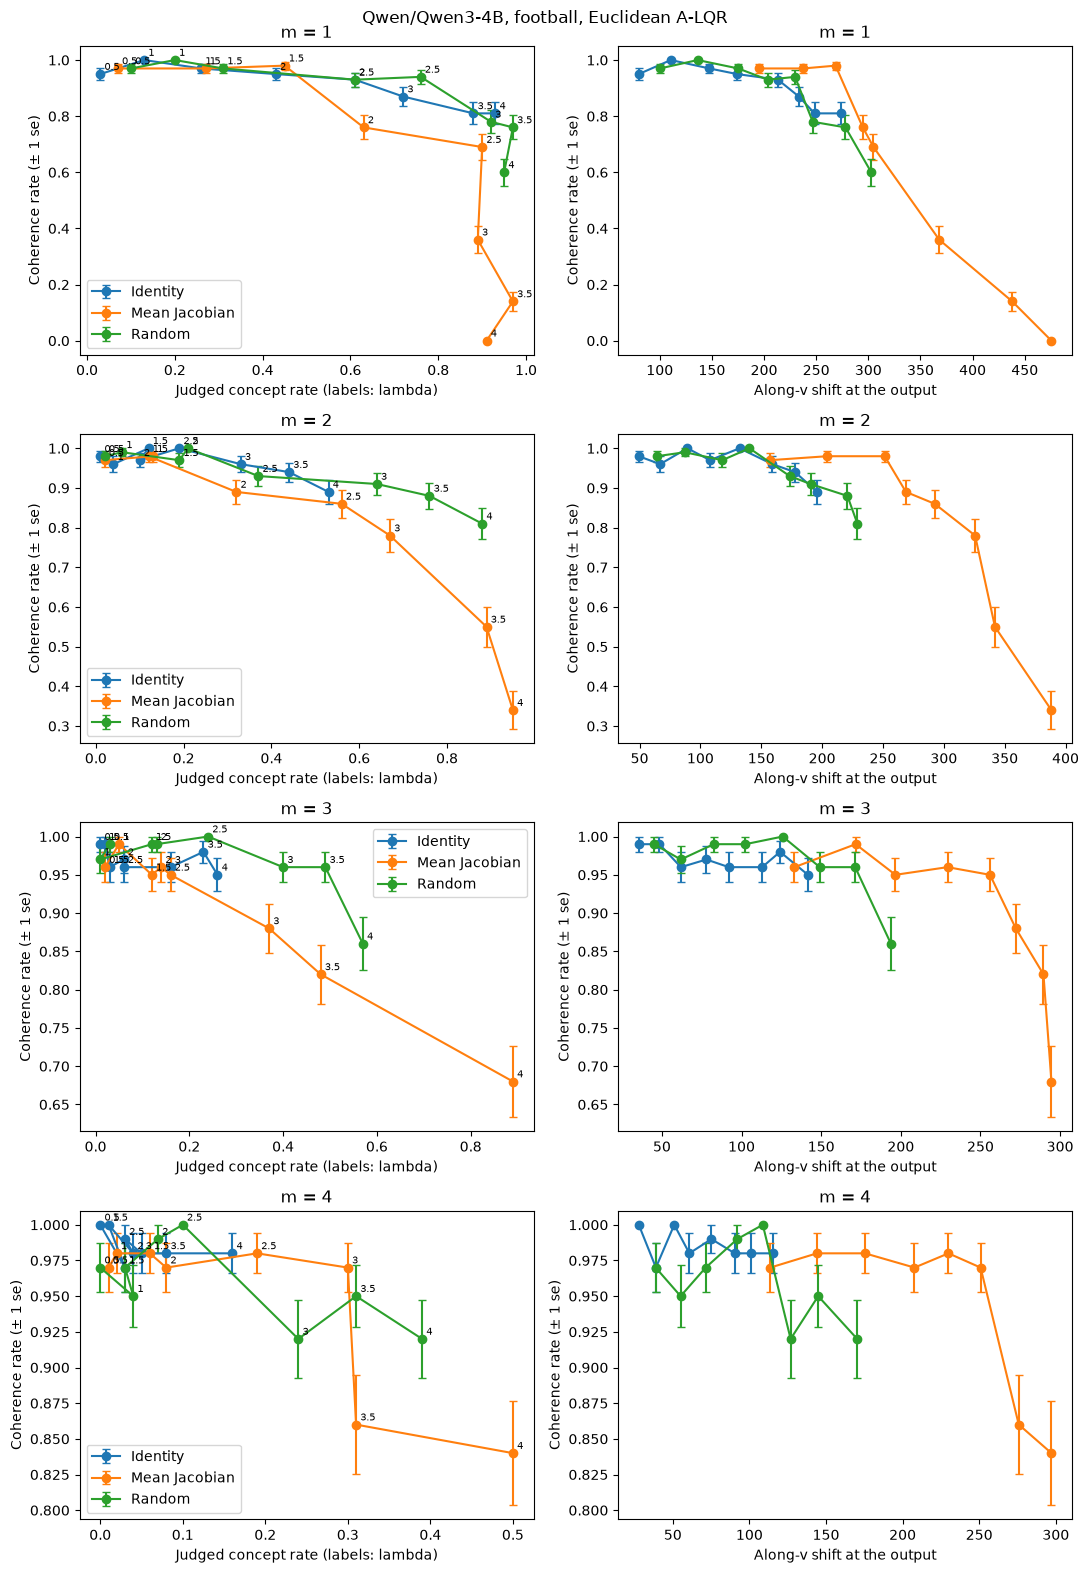

In [7]:
groups = results.groupby(['every', 'operator', 'lambda'], sort=False)
cells = groups[['concept', 'coherent', 'both', 'repetition', 'along_v', 'orthogonal', 'push_energy']].mean()
cells['n'] = groups.size()
print(cells.round(3).to_string(), '\n')

steered = cells.drop(index=0, level='every')
best = steered.loc[steered.groupby(level=['every', 'operator'], sort=False)['both'].idxmax()]
best['± se'] = np.sqrt(best['both'] * (1 - best['both']) / best['n'])
print('Best "both" rate across lambda:')
print(best[['both', '± se', 'concept', 'coherent', 'along_v']].round(3).to_string(), '\n')

fig, axes = plt.subplots(len(EVERY), 2, figsize=(11, 4 * len(EVERY)), squeeze=False)
for row_axes, (every, block) in zip(axes, steered.groupby(level='every', sort=False)):
    # Coherence at along-v shifts that every model reaches at this m; no extrapolation.
    reach = block.groupby(level='operator')['along_v']
    grid = np.linspace(reach.min().max(), reach.max().min(), 4)
    matched = {}
    for name, cell in block.groupby(level='operator', sort=False):
        cell = cell.sort_values('along_v')
        matched[name] = {f'coherent @{a:.3g}': np.interp(a, cell['along_v'], cell['coherent'], left=np.nan, right=np.nan) for a in grid}
        se = np.sqrt(cell['coherent'] * (1 - cell['coherent']) / cell['n'])
        for ax, x in zip(row_axes, ('concept', 'along_v')):
            ax.errorbar(cell[x], cell['coherent'], yerr=se, marker='o', capsize=3, label=name)
        for (_, _, lmbda), point in cell.iterrows():
            row_axes[0].annotate(f'{lmbda:g}', (point['concept'], point['coherent']), fontsize=7,
                                 xytext=(3, 3), textcoords='offset points')
    print(f'm = {every}, coherence at the same along-v shift:')
    print(pd.DataFrame(matched).T.round(2).to_string(), '\n')
    for ax, label in zip(row_axes, ('Judged concept rate (labels: lambda)', 'Along-v shift at the output')):
        ax.set_xlabel(label)
        ax.set_ylabel('Coherence rate (± 1 se)')
        ax.set_title(f'm = {every}')
    row_axes[0].legend()
fig.suptitle(f'{MODEL_NAME}, {CONCEPT}, Euclidean A-LQR')
fig.tight_layout()
fig.savefig(ARTIFACTS / f'ablation_{CONCEPT}.png', dpi=150)
plt.show()

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = results[results['every'] != 0].dropna(subset=['along_v', 'orthogonal', 'push_energy']).copy()
df['coherent'] = df['coherent'].astype(int)
df['log_orth'] = np.log(df['orthogonal'])
df['log_energy'] = np.log(df['push_energy'])

for cols in (['along_v'], ['log_orth'], ['log_energy'], ['along_v', 'log_orth', 'log_energy']):
    model = make_pipeline(StandardScaler(), LogisticRegression())
    auc = cross_val_score(model, df[cols], df['coherent'], cv=5, scoring='roc_auc')
    print(f'{" + ".join(cols):32s} AUC {auc.mean():.3f} +/- {auc.std():.3f}')

base = 'coherent ~ scale(along_v) + scale(log_orth) + scale(log_energy)'
fit = smf.logit(base, df).fit(disp=0)
print(fit.summary2().tables[1].round(3))

full = smf.logit(base + ' + C(operator) + C(every)', df).fit(disp=0)
lr = 2 * (full.llf - fit.llf)
print(f'operator and m beyond the three metrics: LR {lr:.2f}, p = {chi2.sf(lr, full.df_model - fit.df_model):.3f}')

along_v                          AUC 0.843 +/- 0.097
log_orth                         AUC 0.846 +/- 0.081
log_energy                       AUC 0.675 +/- 0.048
along_v + log_orth + log_energy  AUC 0.837 +/- 0.096
                   Coef.  Std.Err.       z  P>|z|  [0.025  0.975]
Intercept          2.961     0.061  48.276  0.000   2.841   3.081
scale(along_v)    -1.370     0.080 -17.185  0.000  -1.526  -1.214
scale(log_orth)    0.031     0.115   0.272  0.786  -0.194   0.257
scale(log_energy) -0.218     0.051  -4.259  0.000  -0.319  -0.118
operator and m beyond the three metrics: LR 68.82, p = 0.000


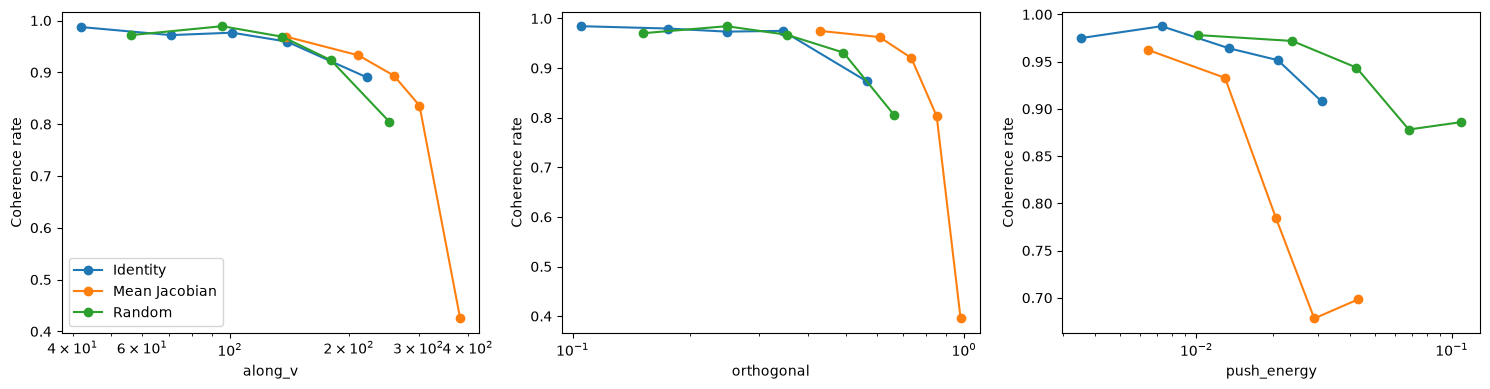

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ('along_v', 'orthogonal', 'push_energy')):
    for name, g in df.groupby('operator'):
        b = g.groupby(pd.qcut(g[col], 5, duplicates='drop'), observed=True)
        ax.plot(b[col].median(), b['coherent'].mean(), marker='o', label=name)
    ax.set_xscale('log')
    ax.set_xlabel(col)
    ax.set_ylabel('Coherence rate')
axes[0].legend()
fig.tight_layout()
plt.show()

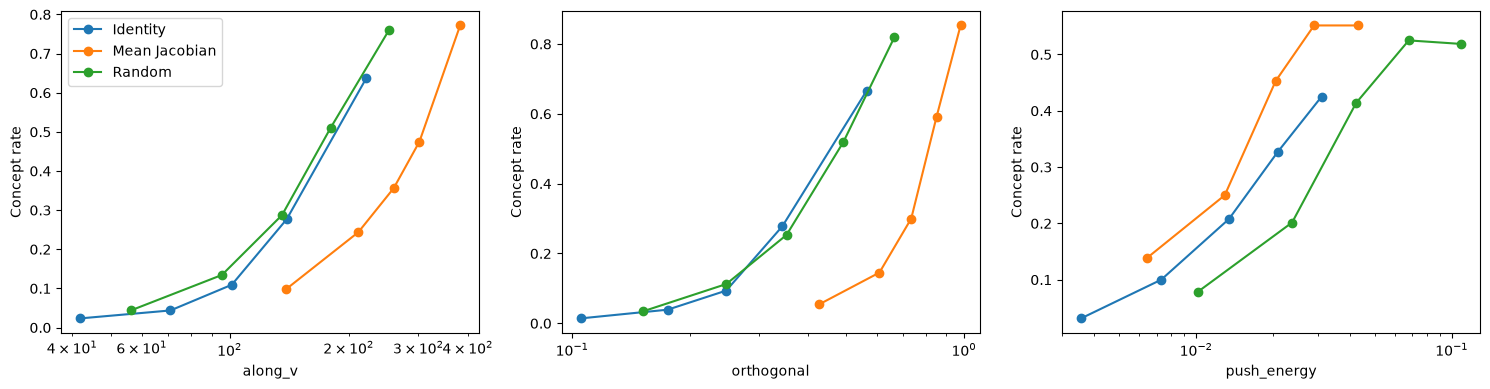

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ('along_v', 'orthogonal', 'push_energy')):
    for name, g in df.groupby('operator'):
        b = g.groupby(pd.qcut(g[col], 5, duplicates='drop'), observed=True)
        ax.plot(b[col].median(), b['concept'].mean(), marker='o', label=name)
    ax.set_xscale('log')
    ax.set_xlabel(col)
    ax.set_ylabel('Concept rate')
axes[0].legend()
fig.tight_layout()
plt.show()